# Task 1 — Exploratory Data Analysis (EDA) on Superstore Retail Sales

**Program:** Datheon Data Analytics & Power BI Internship — Task 1
**Dataset:** Superstore Retail Sales, 2015–2018 (raw starter file: `superstore_sales.csv`)
**Tools:** Python (Pandas, Matplotlib, Seaborn) in Google Colab / Jupyter Notebook

## Objective
Analyse customer purchase volume, monthly seasonality, category-wise revenue, and discount sensitivity.
Formulate at least 5 executive takeaways, supported by reproducible code and charts.

## What this notebook proves
1. The raw file mixes three Excel sheets into one CSV — only 9,994 of 10,800 rows are real orders.
2. Total sales are **\$2,297,200.86** with **\$286,397.02** profit (12.47% margin) across **5,009 orders**.
3. Discounts above 20% destroy profit: every discount band above 20% is loss-making in aggregate.


## 1. Imports and Data Loading

All imports are declared up front. The file is uploaded with the Colab widget, and the
actual uploaded filename is used (this avoids the common `superstore_sales (1).csv` duplicate-name error).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Plot style - clean, readable, print-friendly
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.dpi": 120,
    "font.family": "DejaVu Sans",
    "text.parse_math": False,
})

# Upload the raw starter file.
# In Google Colab this opens the upload widget; in local Jupyter / VS Code
# it falls back to reading superstore_sales.csv from the working folder.
try:
    from google.colab import files
    uploaded = files.upload()
    file_name = list(uploaded.keys())[0]
except ImportError:
    file_name = "superstore_sales.csv"
print(f"Using file: {file_name}")

# Load the raw dataset exactly as supplied
df = pd.read_csv(file_name, low_memory=False)
print(f"Raw dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()


Saving superstore_sales.csv to superstore_sales.csv
Using file: superstore_sales.csv
Raw dataset shape: 10,800 rows x 21 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


## 2. First Inspection — Shape, Columns, and Data Types

Expected raw shape: **10,800 rows × 21 columns**. The extra 806 rows are investigated in Section 3 —
they are not treated as ordinary missing values.

In [ ]:
print("Shape:", df.shape)
print("\nColumns and dtypes:")
print(df.dtypes)
print("\nDuplicate Row IDs in raw file:", df["Row ID"].duplicated().sum())
df.head(3)

Shape: (10800, 21)

Columns and dtypes:
Row ID            object
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code      float64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity         float64
Discount         float64
Profit           float64
dtype: object

Duplicate Row IDs in raw file: 799


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.0,0.0,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.0,0.0,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.0,0.0,6.8714


## 3. Missing-Value Profiling — The Key Finding of This Notebook

Every column except `Row ID` and `Order ID` shows exactly **806 missing values**, and `Postal Code`
shows **817**. That uniform pattern is a structural clue, not random missingness.

**Inspection of the tail of the file shows why:**
- Rows 9,995–10,000 are the **People** sheet: `Row ID` = a person name (e.g. Anna Andreadi), `Order ID` = a region.
- Row 10,001 is the **Returns** sheet header: `Row ID` = "Returned", `Order ID` = "Order ID".
- Rows 10,002–10,800 are the **Returns** sheet: `Row ID` = "Yes", `Order ID` = a returned Order ID.

Somebody exported three Excel sheets (Orders + People + Returns) into a single CSV.
These 806 rows are therefore **not orders** and must be removed structurally — not by blind `dropna`,
which would hide the real cause.

In [ ]:
# Missing-value profile of the RAW file
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (df.isnull().mean() * 100).round(2)
pd.DataFrame({"Missing": missing, "Missing %": missing_pct})

,Missing,Missing %
Category,806,7.46
City,806,7.46
Country,806,7.46
Customer ID,806,7.46
Customer Name,806,7.46
Discount,806,7.46
Order Date,806,7.46
Order ID,0,0.00
Postal Code,817,7.56
Product ID,806,7.46


In [ ]:
# Show the evidence: the last rows are not orders
df.tail(8)[["Row ID", "Order ID", "Order Date", "Sales", "Profit"]]

,Row ID,Order ID,Order Date,Sales,Profit
10792,Yes,US-2018-147886,NaN,NaN,NaN
10793,Yes,US-2018-147886,NaN,NaN,NaN
10794,Yes,US-2018-147886,NaN,NaN,NaN
10795,Yes,US-2018-147886,NaN,NaN,NaN
10796,Yes,US-2018-147998,NaN,NaN,NaN
10797,Yes,US-2018-151127,NaN,NaN,NaN
10798,Yes,US-2018-155999,NaN,NaN,NaN
10799,Yes,US-2018-155999,NaN,NaN,NaN


## 4. Data Cleaning

**Rule:** keep only rows where `Row ID` is numeric. Genuine orders have integer Row IDs (1–9,994);
People rows have names and Returns rows have "Yes" / "Returned", so `pd.to_numeric(..., errors='coerce')`
turns exactly those 806 rows into `NaN` and they are dropped.

`Postal Code` is the only genuine missing field: 11 real orders lack it. It is not used in any
Task 1 analysis, so it is filled with 0 and cast to int rather than dropping 11 valid orders.

In [ ]:
# 4.1 Remove the 806 non-order rows (People + Returns sheets)
before = len(df)
df_clean = df[pd.to_numeric(df["Row ID"], errors="coerce").notna()].copy()
df_clean["Row ID"] = df_clean["Row ID"].astype(int)
print(f"Removed {before - len(df_clean):,} non-order rows")
print(f"Clean shape before type fixes: {df_clean.shape}")

# 4.2 Parse dates
for col in ["Order Date", "Ship Date"]:
    df_clean[col] = pd.to_datetime(df_clean[col], format="%m/%d/%Y", errors="coerce")

# 4.3 Enforce numeric types
for col in ["Sales", "Quantity", "Discount", "Profit"]:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# 4.4 Drop any row still missing a critical field (should be 0 after Step 4.1)
critical = ["Order Date", "Ship Date", "Sales", "Profit", "Quantity",
            "Discount", "Category", "Region", "Segment"]
df_clean = df_clean.dropna(subset=critical).copy()

# 4.5 Fill the only genuine missing field — Postal Code (11 real orders)
df_clean["Postal Code"] = df_clean["Postal Code"].fillna(0).astype(int)

print(f"Final clean shape: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns")
print("Remaining missing values:", int(df_clean.isnull().sum().sum()))
print("Duplicate Row IDs after cleaning:", int(df_clean["Row ID"].duplicated().sum()))
df_clean.head()

Removed 806 non-order rows
Clean shape before type fixes: (9994, 21)
Final clean shape: 9,994 rows x 21 columns
Remaining missing values: 0
Duplicate Row IDs after cleaning: 0


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


## 5. Feature Engineering

Derived columns used throughout the analysis:
- `Year`, `Month`, `Year_Month` — from `Order Date`
- `Margin` = Profit / Sales per line
- `Discount Band` — 0%, 1–10%, 11–20%, 21–30%, 31–50%, 50%+

In [ ]:
df_clean["Year"] = df_clean["Order Date"].dt.year
df_clean["Month"] = df_clean["Order Date"].dt.month
df_clean["Year_Month"] = df_clean["Order Date"].dt.to_period("M").dt.to_timestamp()
df_clean["Margin"] = np.where(df_clean["Sales"] != 0,
                              df_clean["Profit"] / df_clean["Sales"], 0)
bins = [-0.001, 0.0001, 0.10, 0.20, 0.30, 0.50, 1.00]
labels = ["0%", "1-10%", "11-20%", "21-30%", "31-50%", "50%+"]
df_clean["Discount Band"] = pd.cut(df_clean["Discount"], bins=bins, labels=labels)

print(f"Date range: {df_clean['Order Date'].min().date()} to {df_clean['Order Date'].max().date()}")
print(f"Years covered: {sorted(df_clean['Year'].unique())}")
df_clean[["Order Date", "Year", "Month", "Year_Month", "Margin", "Discount Band"]].head()

Date range: 2015-01-03 to 2018-12-30
Years covered: [np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018)]


,Order Date,Year,Month,Year_Month,Margin,Discount Band
0,2017-11-08,2017,11,2017-11-01,0.1600,0%
1,2017-11-08,2017,11,2017-11-01,0.3000,0%
2,2017-06-12,2017,6,2017-06-01,0.4700,0%
3,2016-10-11,2016,10,2016-10-01,-0.4000,31-50%
4,2016-10-11,2016,10,2016-10-01,0.1125,11-20%


## 6. Key Performance Indicators (KPIs)

Headline result: **\$2,297,200.86 sales, \$286,397.02 profit, 12.47% margin, 5,009 orders,
37,873 units, 793 customers, 1,862 products.**

In [ ]:
kpi = pd.DataFrame({
    "KPI": ["Total Sales ($)", "Total Profit ($)", "Profit Margin (%)", "Total Orders",
            "Order Lines", "Units Sold", "Unique Customers", "Unique Products",
            "Average Discount (%)", "Loss-Making Lines", "Loss Amount ($)"],
    "Value": [round(df_clean["Sales"].sum(), 2), round(df_clean["Profit"].sum(), 2),
              round(df_clean["Profit"].sum() / df_clean["Sales"].sum() * 100, 2),
              int(df_clean["Order ID"].nunique()), len(df_clean),
              int(df_clean["Quantity"].sum()), int(df_clean["Customer ID"].nunique()),
              int(df_clean["Product ID"].nunique()),
              round(df_clean["Discount"].mean() * 100, 2),
              int((df_clean["Profit"] < 0).sum()),
              round(df_clean.loc[df_clean["Profit"] < 0, "Profit"].sum(), 2)]
})
kpi

,KPI,Value
0,Total Sales ($),2297200.86
1,Total Profit ($),286397.02
2,Profit Margin (%),12.47
3,Total Orders,5009.00
4,Order Lines,9994.00
5,Units Sold,37873.00
6,Unique Customers,793.00
7,Unique Products,1862.00
8,Average Discount (%),15.62
9,Loss-Making Lines,1871.00


## 7. Year-on-Year Trend

Sales dipped **-2.8%** in 2016, then grew **+29.5%** in 2017 and **+20.4%** in 2018.
The strongest single-year gain was **2017 (+\$138,673)**, not 2018 (+\$124,010).

In [ ]:
yoy = (df_clean.groupby("Year")
         .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
              Orders=("Order ID", "nunique"))
         .reset_index())
yoy["Margin %"] = (yoy["Profit"] / yoy["Sales"] * 100).round(2)
yoy["YoY Sales %"] = (yoy["Sales"].pct_change() * 100).round(1)
yoy

,Year,Sales,Profit,Orders,Margin %,YoY Sales %
0,2015,484247.4981,49543.9741,969,10.23,NaN
1,2016,470532.5090,61618.6037,1038,13.10,-2.8
2,2017,609205.5980,81795.1743,1315,13.43,29.5
3,2018,733215.2552,93439.2696,1687,12.74,20.4


## 8. Monthly Sales Velocity (Seasonality)

**Chart rule applied here:** 48 monthly labels are never all printed — every 6th month is shown
and labels are rotated 45°, so the x-axis stays readable (this was the overlapping-label flaw
in the first draft). Sales peak in Q4 (Nov–Dec) in most years — holiday seasonality.

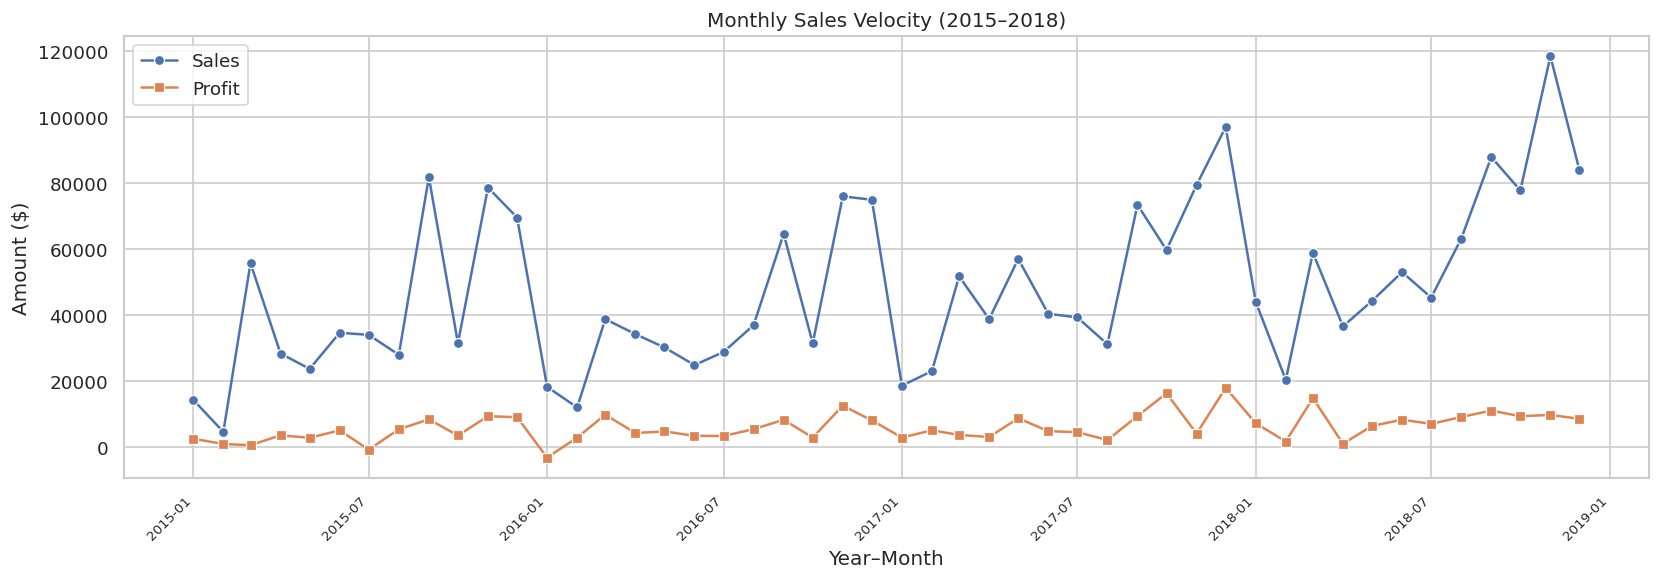

In [ ]:
monthly_sales = (df_clean.groupby("Year_Month")
                   .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
                   .reset_index())

fig, ax = plt.subplots(figsize=(14, 5))
sns.lineplot(data=monthly_sales, x="Year_Month", y="Sales", marker="o", ax=ax, label="Sales")
sns.lineplot(data=monthly_sales, x="Year_Month", y="Profit", marker="s", ax=ax, label="Profit")
ax.set_title("Monthly Sales Velocity (2015–2018)")
ax.set_xlabel("Year–Month")
ax.set_ylabel("Amount ($)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.tight_layout()
plt.show()

## 9. Category-Wise Revenue and Profit

Technology is the profit engine (**\$836,154 sales, \$145,455 profit, 17.4% margin**).
Furniture is a revenue trap (**\$742,000 sales but only \$18,451 profit, 2.5% margin**).

In [ ]:
cat = (df_clean.groupby("Category")
        .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Lines=("Sales", "size"))
        .reset_index())
cat["Margin %"] = (cat["Profit"] / cat["Sales"] * 100).round(2)
cat = cat.sort_values("Sales", ascending=False)
cat

,Category,Sales,Profit,Lines,Margin %
2,Technology,836154.0330,145454.9481,1847,17.40
0,Furniture,741999.7953,18451.2728,2121,2.49
1,Office Supplies,719047.0320,122490.8008,6026,17.04


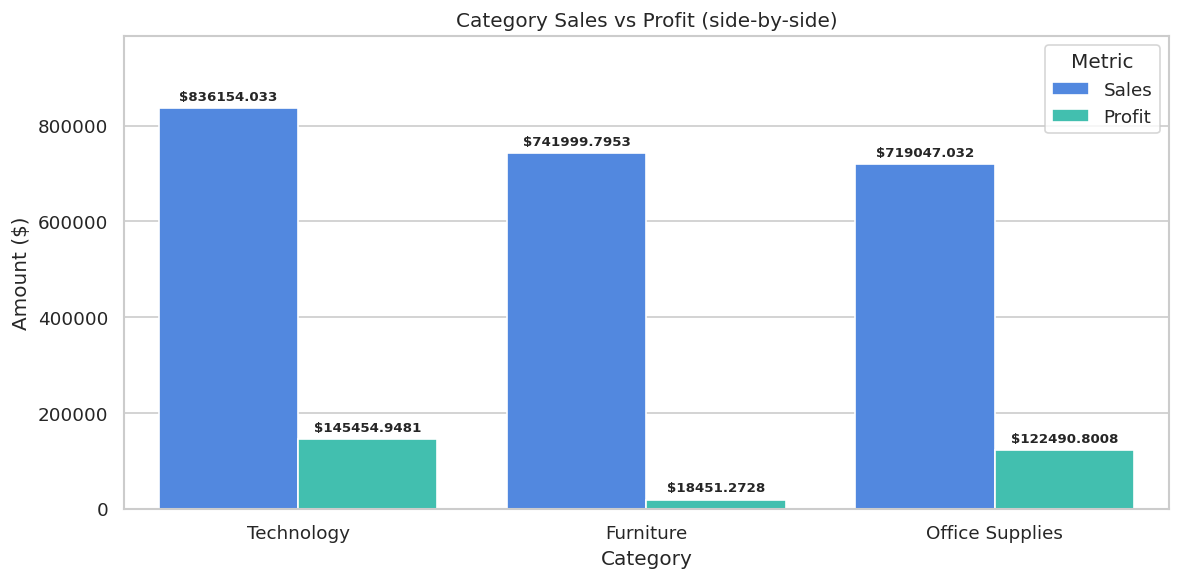

In [ ]:
# Category Sales vs Profit - side-by-side grouped bars (dodge=True).
# The previous version plotted Sales and Profit on the same x-position,
# so the smaller Profit bar was hidden inside the Sales bar.
cat_long = cat.melt(id_vars="Category", value_vars=["Sales", "Profit"], var_name="Metric", value_name="Amount")
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=cat_long, x="Category", y="Amount", hue="Metric", palette={"Sales": "#3B82F6", "Profit": "#2DD4BF"}, dodge=True, ax=ax)
for bar in ax.containers:
    ax.bar_label(bar, fmt="$%s", padding=3, fontsize=8, weight="bold")
ax.set_title("Category Sales vs Profit (side-by-side)")
ax.set_ylabel("Amount ($)")
ax.set_ylim(0, cat["Sales"].max() * 1.18)
plt.tight_layout()
plt.show()


## 10. Sub-Category Profit — Only 3 Loss-Makers

Only **3 of 17** sub-categories lose money in aggregate: **Tables (-\$17,725), Bookcases (-\$3,473),
Supplies (-\$1,189)**. The other 14 are profitable. Any "worst 8 negative" chart would therefore
be misleading — the honest chart shows all sub-categories ranked, or only the 3 true loss-makers.

In [ ]:
sub = (df_clean.groupby("Sub-Category")
        .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
        .reset_index())
sub["Margin %"] = (sub["Profit"] / sub["Sales"] * 100).round(2)
sub = sub.sort_values("Profit")
sub

,Sub-Category,Sales,Profit,Margin %
16,Tables,206965.5320,-17725.4811,-8.56
4,Bookcases,114879.9963,-3472.5560,-3.02
15,Supplies,46673.5380,-1189.0995,-2.55
8,Fasteners,3024.2800,949.5182,31.40
11,Machines,189238.6310,3384.7569,1.79
10,Labels,12486.3120,5546.2540,44.42
2,Art,27118.7920,6527.7870,24.07
7,Envelopes,16476.4020,6964.1767,42.27
9,Furnishings,91705.1640,13059.1436,14.24
1,Appliances,107532.1610,18138.0054,16.87


## 11. Region and Customer Segment

West is the largest market (**\$725,458 sales, \$108,418 profit, 14.9% margin**); Central lags
(**\$501,240 sales, \$39,706 profit, 7.9% margin**). Consumer is the dominant segment
(**\$1,161,401 sales, 50.6% of revenue**).

In [ ]:
reg = (df_clean.groupby("Region")
        .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
        .reset_index())
reg["Margin %"] = (reg["Profit"] / reg["Sales"] * 100).round(2)
reg = reg.sort_values("Sales", ascending=False)
reg

,Region,Sales,Profit,Margin %
3,West,725457.8245,108418.4489,14.94
1,East,678781.2400,91522.7800,13.48
0,Central,501239.8908,39706.3625,7.92
2,South,391721.9050,46749.4303,11.93


In [ ]:
seg = (df_clean.groupby("Segment")
        .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
        .reset_index())
seg["Margin %"] = (seg["Profit"] / seg["Sales"] * 100).round(2)
seg["Share %"] = (seg["Sales"] / seg["Sales"].sum() * 100).round(1)
seg = seg.sort_values("Sales", ascending=False)
seg

,Segment,Sales,Profit,Margin %,Share %
0,Consumer,1.161401e+06,134119.2092,11.55,50.6
1,Corporate,7.061464e+05,91979.1340,13.03,30.7
2,Home Office,4.296531e+05,60298.6785,14.03,18.7


## 12. Discount Sensitivity — The Core Finding

Every discount band above 20% is loss-making in aggregate:

| Discount Band | Profit |
|---|---|
| 0% | +\$320,988 |
| 1–10% | +\$9,029 |
| 11–20% | +\$91,756 |
| 21–30% | -\$10,369 |
| 31–50% | -\$48,448 |
| 50%+ | -\$76,559 |

Separately, **1,871 lines (18.7%)** are loss-making, losing **-\$156,131** in total. Those two facts
must not be conflated: the 1,871 loss lines span all discount levels; the band table shows
*where* the aggregate loss concentrates.

In [ ]:
band = (df_clean.groupby("Discount Band", observed=True)
        .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Lines=("Sales", "size"))
        .reset_index())
band["Margin %"] = (band["Profit"] / band["Sales"] * 100).round(2)
band

,Discount Band,Sales,Profit,Lines,Margin %
0,0%,1.087908e+06,320987.6032,4798,29.51
1,1-10%,5.436935e+04,9029.1770,94,16.61
2,11-20%,7.921529e+05,91756.2975,3709,11.58
3,21-30%,1.032267e+05,-10369.2774,227,-10.05
4,31-50%,1.953148e+05,-48447.7273,310,-24.80
5,50%+,6.422874e+04,-76559.0513,856,-119.20


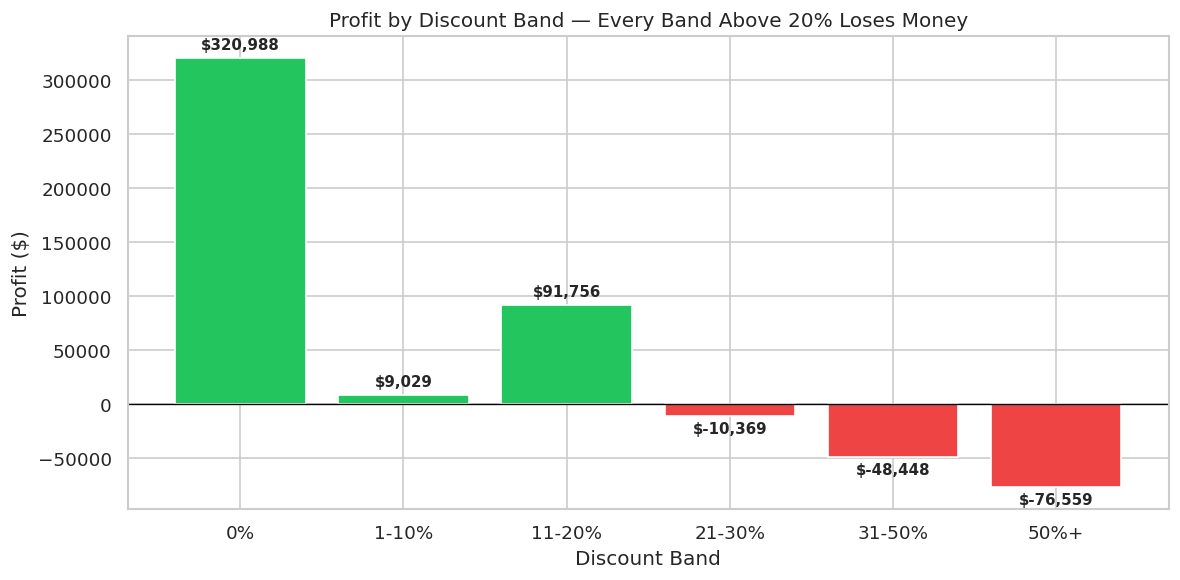

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#22C55E" if p > 0 else "#EF4444" for p in band["Profit"]]
ax.bar(band["Discount Band"], band["Profit"], color=colors)
ax.axhline(0, color="black", linewidth=0.8)
for i, row in band.iterrows():
    ax.text(row["Discount Band"], row["Profit"] + (8000 if row["Profit"] > 0 else -16000),
            f"${row['Profit']:,.0f}", ha="center", fontsize=9, weight="bold")
ax.set_title("Profit by Discount Band — Every Band Above 20% Loses Money")
ax.set_xlabel("Discount Band")
ax.set_ylabel("Profit ($)")
plt.tight_layout()
plt.show()

## 13. Discount vs Profit — Scatter (Required Chart)

Each dot is one order line. The red dashed line is break-even (Profit = 0).
Loss-making dots cluster at high discounts, while the largest profits sit at 0–20% discount.

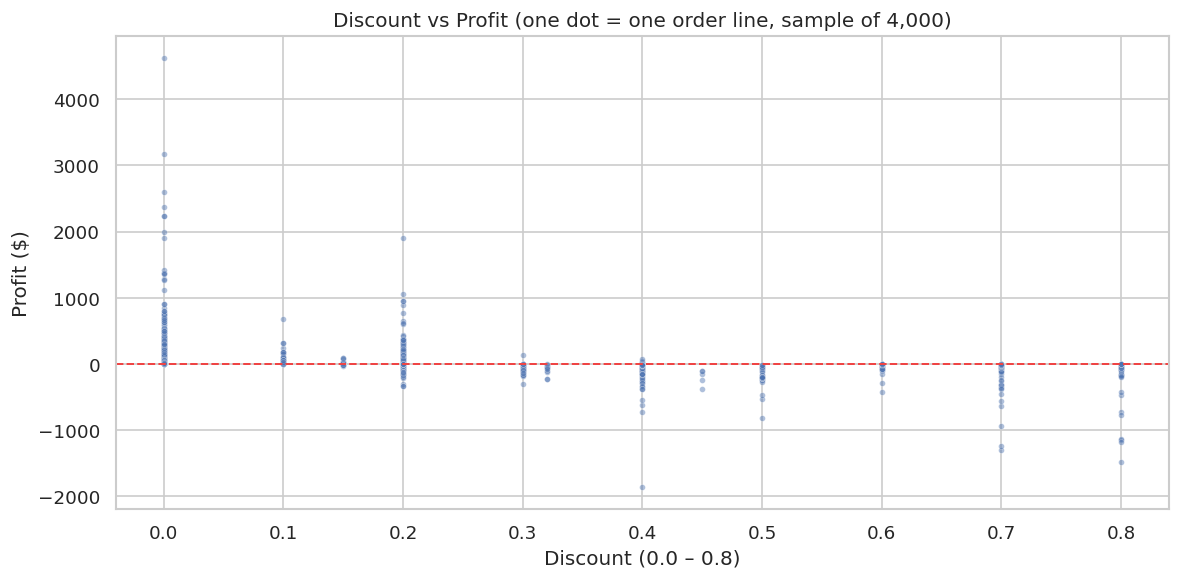

In [ ]:
sample = df_clean.sample(min(4000, len(df_clean)), random_state=7)
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=sample, x="Discount", y="Profit", s=12, alpha=0.45, ax=ax)
ax.axhline(0, color="#EF4444", linestyle="--", linewidth=1.2)
ax.set_title("Discount vs Profit (one dot = one order line, sample of 4,000)")
ax.set_xlabel("Discount (0.0 – 0.8)")
ax.set_ylabel("Profit ($)")
plt.tight_layout()
plt.show()

## 14. Executive Takeaways — At Least 5 Business Findings

1. **Technology is the profit engine.** Technology delivers \$836K (36.4%) of revenue at 17.4% margin —
   \$145K profit, more than Furniture and Office Supplies combined in profit terms. Protect its pricing.
2. **Furniture is a revenue trap.** Furniture sells \$742K but returns only \$18.5K profit (2.5% margin).
   Tables alone lose **-\$17,725**. Reprice, renegotiate cost, or restrict discounting on Tables and Bookcases.
3. **Discounts above 20% are value-destructive.** The 21–30% band loses -\$10K, 31–50% loses -\$48K,
   and 50%+ loses -\$77K. A cap near 20% (with exceptions requiring approval) is the single largest profit lever.
4. **1,871 lines (18.7%) lose money, -\$156K in total.** Loss is not one bad product — it is spread
   across lines and concentrated in high-discount bands. Line-level discount approval would catch most of it.
5. **Growth is real but uneven.** Sales grew from \$484K (2015) to \$733K (2018), +51% in 3 years, with the
   strongest gain in 2017 (+29.5%). The 2016 dip (-2.8%) shows growth is not automatic.
6. **West + East carry the business; Central lags.** West (\$725K, 14.9% margin) and East (\$679K, 13.5%)
   supply 61% of sales. Central (\$501K, 7.9% margin) needs a margin review, not just more volume.
7. **Consumer dominates.** Consumer is 50.6% of revenue (\$1.16M). Retention in Consumer matters more
   than acquiring small Home Office volume.


## 15. Save the Clean Dataset (for Task 2)

The clean file is saved for reuse in Task 2 (Power BI dashboard). It contains only the 9,994
genuine order lines, with derived columns.

In [ ]:
df_clean.to_csv("superstore_clean.csv", index=False)
print(f"Saved superstore_clean.csv — {len(df_clean):,} rows")
df_clean.head(3)

Saved superstore_clean.csv — 9,994 rows


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Year_Month,Margin,Discount Band
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bush Somerset Collection Bookcase,261.96,2.0,0.0,41.9136,2017,11,2017-11-01,0.16,0%
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.0,0.0,219.5820,2017,11,2017-11-01,0.30,0%
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Self-Adhesive Address Labels for Typewriters b...,14.62,2.0,0.0,6.8714,2017,6,2017-06-01,0.47,0%


## Limitations and Next Steps
- Returns data (800 rows) records *which* orders were returned, but without return dates or amounts
  it cannot be joined into a returns-rate analysis — it was excluded, not analysed as orders.
- Postal Code was filled with 0 for 11 orders; it is not used in any analysis here.
- Next step (Task 2): build the Power BI executive dashboard from `superstore_clean.csv`,
  reusing these KPIs, the discount-band table, and the category/region breakdowns.
